Sky Wong

## Database Schema Setup (SQLite)

### Subtask:
Initialize the SQLite database with tables for companies, portfolio, transactions, holdings, and prices, and insert baseline data.


**Reasoning**:
Create the database tables and populate them with the specified baseline data in SQLite.



In [1]:
import sqlite3

# 1. Connect to the database
conn = sqlite3.connect('portfolio_analytics.db')
cursor = conn.cursor()

# 2. Enable foreign key support
cursor.execute('PRAGMA foreign_keys = ON;')

# 3. Create tables
cursor.execute('''
CREATE TABLE IF NOT EXISTS companies (
    ticker TEXT PRIMARY KEY,
    company_name TEXT NOT NULL,
    sector TEXT NOT NULL,
    market_cap REAL
);
''')

cursor.execute('''
CREATE TABLE IF NOT EXISTS portfolio (
    portfolio_id INTEGER PRIMARY KEY AUTOINCREMENT,
    portfolio_name TEXT NOT NULL,
    inception_date TEXT NOT NULL,
    base_currency TEXT NOT NULL DEFAULT 'USD'
);
''')

cursor.execute('''
CREATE TABLE IF NOT EXISTS transactions (
    transaction_id INTEGER PRIMARY KEY AUTOINCREMENT,
    portfolio_id INTEGER NOT NULL,
    ticker TEXT NOT NULL,
    transaction_type TEXT CHECK(transaction_type IN ('BUY', 'SELL')) NOT NULL,
    quantity REAL NOT NULL CHECK(quantity > 0),
    price REAL NOT NULL CHECK(price > 0),
    transaction_date TEXT NOT NULL,
    FOREIGN KEY (portfolio_id) REFERENCES portfolio(portfolio_id),
    FOREIGN KEY (ticker) REFERENCES companies(ticker)
);
''')

cursor.execute('''
CREATE TABLE IF NOT EXISTS holdings (
    holding_id INTEGER PRIMARY KEY AUTOINCREMENT,
    portfolio_id INTEGER NOT NULL,
    ticker TEXT NOT NULL,
    shares REAL NOT NULL CHECK(shares >= 0),
    average_cost REAL NOT NULL CHECK(average_cost >= 0),
    last_updated TEXT NOT NULL,
    FOREIGN KEY (portfolio_id) REFERENCES portfolio(portfolio_id),
    FOREIGN KEY (ticker) REFERENCES companies(ticker),
    UNIQUE(portfolio_id, ticker)
);
''')

cursor.execute('''
CREATE TABLE IF NOT EXISTS prices (
    price_id INTEGER PRIMARY KEY AUTOINCREMENT,
    ticker TEXT NOT NULL,
    price_date TEXT NOT NULL,
    close_price REAL NOT NULL CHECK(close_price > 0),
    FOREIGN KEY (ticker) REFERENCES companies(ticker),
    UNIQUE(ticker, price_date)
);
''')

# 4. Populate companies table with baseline metadata
companies_data = [
    ('AAPL', 'Apple Inc.', 'Technology', 3000000000000.0),
    ('MSFT', 'Microsoft Corporation', 'Technology', 3100000000000.0),
    ('JPM', 'JPMorgan Chase & Co.', 'Financial Services', 550000000000.0),
    ('SPY', 'SPDR S&P 500 ETF Trust', 'Exchange Traded Funds', 500000000000.0),
    ('TLT', 'iShares 20+ Year Treasury Bond ETF', 'Exchange Traded Funds', 40000000000.0)
]
cursor.executemany('''
INSERT OR IGNORE INTO companies (ticker, company_name, sector, market_cap)
VALUES (?, ?, ?, ?);
''', companies_data)

# 5. Populate portfolio table with 'Aletheia Global Capital'
cursor.execute('''
INSERT OR IGNORE INTO portfolio (portfolio_id, portfolio_name, inception_date, base_currency)
VALUES (1, 'Aletheia Global Capital', '2023-01-01', 'USD');
''')

# 6. Commit and close
conn.commit()
conn.close()
print("Database initialized and populated with baseline data successfully.")

Database initialized and populated with baseline data successfully.


## Data Acquisition and Cleaning Pipeline

### Subtask:
Develop a modular data pipeline to fetch historical market data from yfinance, clean it, and load it into the database.


**Reasoning**:
Develop the data acquisition and cleaning pipeline using yfinance to fetch and clean historical data for AAPL, MSFT, JPM, SPY, and TLT, then insert it into the SQLite database and verify the insertion.



In [4]:
import sqlite3
import datetime
import pandas as pd
import yfinance as yf

# 1. Define tickers and date range
tickers = ['AAPL', 'MSFT', 'JPM', 'SPY', 'TLT']
start_date = '2023-01-01'
end_date = datetime.date.today().strftime('%Y-%m-%d')

print(f"Fetching data from {start_date} to {end_date}...")

# 2. Fetch data from yfinance
raw_data = yf.download(tickers, start=start_date, end=end_date, group_by='ticker', auto_adjust=True, progress=False)

# 3. Clean and process data
price_records = []
for ticker in tickers:
    if ticker in raw_data.columns.levels[0]:
        ticker_df = raw_data[ticker].copy()
        # Forward-fill then backward-fill to handle market holidays and missing values
        ticker_df['Close'] = ticker_df['Close'].ffill().bfill()

        for date, row in ticker_df.iterrows():
            close_price = float(row['Close'])
            # Skip if NaN still persists
            if pd.isna(close_price):
                continue
            date_str = date.strftime('%Y-%m-%d')
            price_records.append((ticker, date_str, close_price))

print(f"Total processed records: {len(price_records)}")

# 4. Insert into SQLite database
conn = sqlite3.connect('portfolio_analytics.db')
cursor = conn.cursor()
cursor.execute('PRAGMA foreign_keys = ON;')

# Insert records using INSERT OR REPLACE to update close_prices if run multiple times
cursor.executemany('''
INSERT OR REPLACE INTO prices (ticker, price_date, close_price)
VALUES (?, ?, ?);
''', price_records)

conn.commit()

# 5. Verification
cursor.execute('SELECT COUNT(*) FROM prices;')
total_rows = cursor.fetchone()[0]

print(f"Verification: Total rows in 'prices' table: {total_rows}")

print("\nSample database records:")
cursor.execute('SELECT * FROM prices LIMIT 5;')
for row in cursor.fetchall():
    print(row)

conn.close()
print("SUCCESS")

Fetching data from 2023-01-01 to 2026-10-06...
Total processed records: 4710
Verification: Total rows in 'prices' table: 4710

Sample database records:
(9421, 'AAPL', '2023-01-03', 122.87673950195312)
(9422, 'AAPL', '2023-01-04', 124.14412689208984)
(9423, 'AAPL', '2023-01-05', 122.8276138305664)
(9424, 'AAPL', '2023-01-06', 127.34695434570312)
(9425, 'AAPL', '2023-01-09', 127.86763000488281)
SUCCESS


## Quantitative Performance & Risk Engine

### Subtask:
Implement a Python engine to calculate portfolio-level metrics and individual asset returns.


**Reasoning**:
I will create a Python code block to implement the Quantitative Performance & Risk Engine subtask. This includes: inserting transactions and holdings to set up the portfolio, querying historical prices, calculating daily log returns, calculating annualized volatilities, covariance matrix, portfolio returns, Sharpe ratio, Beta, Alpha, and Maximum Drawdown, and formatting the results into DataFrames.



In [5]:
import sqlite3
import pandas as pd
import numpy as np

# 1. Connect to SQLite database and set up transactions and holdings
conn = sqlite3.connect('portfolio_analytics.db')
cursor = conn.cursor()
cursor.execute('PRAGMA foreign_keys = ON;')

# Clear existing transactions/holdings if any to prevent duplicate constraint issues
cursor.execute('DELETE FROM transactions;')
cursor.execute('DELETE FROM holdings;')

# Insert BUY transactions (early 2023)
# Portfolio ID: 1, Benchmark SPY is not directly held in the active portfolio but used for Beta/Alpha
transactions_data = [
    (1, 'AAPL', 'BUY', 150.0, 130.0, '2023-01-10'),
    (1, 'MSFT', 'BUY', 100.0, 240.0, '2023-01-10'),
    (1, 'JPM', 'BUY', 120.0, 125.0, '2023-01-10'),
    (1, 'TLT', 'BUY', 200.0, 105.0, '2023-01-10')
]

cursor.executemany('''
INSERT INTO transactions (portfolio_id, ticker, transaction_type, quantity, price, transaction_date)
VALUES (?, ?, ?, ?, ?, ?);
''', transactions_data)

# Insert matching holdings
holdings_data = [
    (1, 'AAPL', 150.0, 130.0, '2023-01-10'),
    (1, 'MSFT', 100.0, 240.0, '2023-01-10'),
    (1, 'JPM', 120.0, 125.0, '2023-01-10'),
    (1, 'TLT', 200.0, 105.0, '2023-01-10')
]

cursor.executemany('''
INSERT INTO holdings (portfolio_id, ticker, shares, average_cost, last_updated)
VALUES (?, ?, ?, ?, ?);
''', holdings_data)

conn.commit()

# 2. Fetch price data for the active date range (from 2023-01-10 onwards)
query = """
SELECT ticker, price_date, close_price
FROM prices
WHERE price_date >= '2023-01-10'
ORDER BY price_date, ticker;
"""
prices_df = pd.read_sql_query(query, conn)
conn.close()

# Pivot prices to have tickers as columns
pivot_prices = prices_df.pivot(index='price_date', columns='ticker', values='close_price').dropna()

# 3. Calculate daily log returns
log_returns = np.log(pivot_prices / pivot_prices.shift(1)).dropna()

# 4. Calculate individual asset weights as of average cost values
assets = ['AAPL', 'MSFT', 'JPM', 'TLT']
holdings_val = {
    'AAPL': 150.0 * 130.0,
    'MSFT': 100.0 * 240.0,
    'JPM': 120.0 * 125.0,
    'TLT': 200.0 * 105.0
}
total_cost_val = sum(holdings_val.values())
weights = np.array([holdings_val[asset] / total_cost_val for asset in assets])

# Calculate asset returns and volatility
asset_returns = log_returns[assets]
benchmark_returns = log_returns['SPY']

# Annualized Individual Volatilities
annual_vol = asset_returns.std() * np.sqrt(252)

# Covariance Matrix
cov_matrix = asset_returns.cov()

# Portfolio Volatility: sqrt(w^T * Cov * w) * sqrt(252)
portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
portfolio_vol_annual = np.sqrt(portfolio_variance) * np.sqrt(252)

# Portfolio Daily returns
portfolio_daily_returns = asset_returns.dot(weights)

# 5. Key Risk Metrics
# Annualized Sharpe Ratio (Rf = 0%)
portfolio_mean_return_annual = portfolio_daily_returns.mean() * 252
sharpe_ratio = portfolio_mean_return_annual / portfolio_vol_annual

# Beta and Alpha against SPY
cov_with_benchmark = np.cov(portfolio_daily_returns, benchmark_returns)[0, 1]
benchmark_variance = benchmark_returns.var()
portfolio_beta = cov_with_benchmark / benchmark_variance

# Annualized Alpha: Rp - Beta * Rm
benchmark_mean_return_annual = benchmark_returns.mean() * 252
portfolio_alpha = portfolio_mean_return_annual - (portfolio_beta * benchmark_mean_return_annual)

# Maximum Drawdown
cumulative_returns = np.exp(portfolio_daily_returns.cumsum())
running_max = cumulative_returns.cummax()
drawdowns = (cumulative_returns - running_max) / running_max
max_drawdown = drawdowns.min()

# 6. Format results into DataFrames
asset_metrics = pd.DataFrame({
    'Weight (%)': [holdings_val[asset]/total_cost_val * 100 for asset in assets],
    'Annualized Volatility (%)': (annual_vol * 100).values
}, index=assets)

portfolio_metrics = pd.DataFrame({
    'Metric': [
        'Annualized Return',
        'Annualized Volatility',
        'Sharpe Ratio (Rf=0)',
        'Beta vs SPY',
        'Annualized Alpha',
        'Maximum Drawdown'
    ],
    'Value': [
        f"{portfolio_mean_return_annual * 100:.2f}%",
        f"{portfolio_vol_annual * 100:.2f}%",
        f"{sharpe_ratio:.2f}",
        f"{portfolio_beta:.2f}",
        f"{portfolio_alpha * 100:.2f}%",
        f"{max_drawdown * 100:.2f}%"
    ]
})

print("=== INDIVIDUAL ASSET METRICS ===")
print(asset_metrics.round(2))
print("\n=== PORTFOLIO RISK & PERFORMANCE METRICS ===")
print(portfolio_metrics)

=== INDIVIDUAL ASSET METRICS ===
      Weight (%)  Annualized Volatility (%)
AAPL       24.53                      25.68
MSFT       30.19                      26.02
JPM        18.87                      22.98
TLT        26.42                      14.09

=== PORTFOLIO RISK & PERFORMANCE METRICS ===
                  Metric    Value
0      Annualized Return   17.09%
1  Annualized Volatility   14.28%
2    Sharpe Ratio (Rf=0)     1.20
3            Beta vs SPY     0.77
4       Annualized Alpha    1.97%
5       Maximum Drawdown  -17.10%


## Advanced SQL Portfolio Analytics Queries

### Subtask:
Write and execute production-grade SQL queries to answer critical portfolio and risk analysis questions.


**Reasoning**:
I will execute a Python code block to connect to the SQLite database and run advanced SQL queries for sector allocation, return attribution, and performance drawdown analysis, then display the results as formatted Pandas DataFrames.



In [7]:
import sqlite3
import pandas as pd

# 1. Connect to the SQLite database
conn = sqlite3.connect('portfolio_analytics.db')

# 2. Get the latest price date available in the database
latest_date_df = pd.read_sql_query("SELECT MAX(price_date) as max_date FROM prices;", conn)
latest_date = latest_date_df['max_date'].iloc[0]
print(f"Latest price date in database: {latest_date}\n")

# Query A: Current Portfolio Allocation by Sector
sector_query = f"""
WITH PositionValues AS (
    SELECT
        h.ticker,
        c.sector,
        h.shares * p.close_price AS market_value
    FROM holdings h
    JOIN companies c ON h.ticker = c.ticker
    JOIN prices p ON h.ticker = p.ticker
    WHERE p.price_date = '{latest_date}'
),
TotalPortfolio AS (
    SELECT SUM(market_value) AS total_val FROM PositionValues
)
SELECT
    pv.sector,
    ROUND(SUM(pv.market_value), 2) AS sector_market_value,
    ROUND((SUM(pv.market_value) / tp.total_val) * 100, 2) AS allocation_percentage
FROM PositionValues pv, TotalPortfolio tp
GROUP BY pv.sector
ORDER BY allocation_percentage DESC;
"""

# Query B: Return Attribution / Realized & Unrealized P&L by Asset
attribution_query = f"""
SELECT
    h.ticker,
    c.company_name,
    h.shares,
    h.average_cost,
    ROUND(h.shares * h.average_cost, 2) AS total_cost,
    ROUND(p.close_price, 2) AS current_price,
    ROUND(h.shares * p.close_price, 2) AS current_value,
    ROUND((h.shares * p.close_price) - (h.shares * h.average_cost), 2) AS absolute_pnl,
    ROUND((((p.close_price - h.average_cost) / h.average_cost) * 100), 2) AS percentage_return
FROM holdings h
JOIN companies c ON h.ticker = c.ticker
JOIN prices p ON h.ticker = p.ticker
WHERE p.price_date = '{latest_date}'
ORDER BY absolute_pnl DESC;
"""

# Query C: Historical Performance and Drawdown Analysis by Asset
drawdown_query = """
WITH HistoricalMax AS (
    SELECT
        ticker,
        price_date,
        close_price,
        MAX(close_price) OVER (
            PARTITION BY ticker
            ORDER BY price_date
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS peak_price
    FROM prices
    WHERE price_date >= '2023-01-10'
),
Drawdowns AS (
    SELECT
        ticker,
        price_date,
        close_price,
        peak_price,
        ((close_price - peak_price) / peak_price) * 100 AS drawdown_pct
    FROM HistoricalMax
),
MinDrawdowns AS (
    SELECT
        ticker,
        MIN(drawdown_pct) AS max_historical_drawdown_pct
    FROM Drawdowns
    GROUP BY ticker
)
SELECT
    md.ticker,
    ROUND(md.max_historical_drawdown_pct, 2) AS max_historical_drawdown_pct,
    MIN(d.price_date) AS worst_day
FROM MinDrawdowns md
JOIN Drawdowns d ON md.ticker = d.ticker AND md.max_historical_drawdown_pct = d.drawdown_pct
GROUP BY md.ticker
ORDER BY max_historical_drawdown_pct ASC;
"""

# Execute and print queries
sector_df = pd.read_sql_query(sector_query, conn)
attribution_df = pd.read_sql_query(attribution_query, conn)
drawdown_df = pd.read_sql_query(drawdown_query, conn)

conn.close()

print("=== PORTFOLIO SECTOR ALLOCATION ===")
print(sector_df.to_string(index=False))
print("\n=== RETURN ATTRIBUTION BY ASSET ===")
print(attribution_df.to_string(index=False))
print("\n=== MAXIMUM HISTORICAL DRAWDOWN BY ASSET ===")
print(drawdown_df.to_string(index=False))

Latest price date in database: 2026-10-05

=== PORTFOLIO SECTOR ALLOCATION ===
               sector  sector_market_value  allocation_percentage
           Technology             102451.5                  64.94
   Financial Services              39885.6                  25.28
Exchange Traded Funds              15422.0                   9.78

=== RETURN ATTRIBUTION BY ASSET ===
ticker                       company_name  shares  average_cost  total_cost  current_price  current_value  absolute_pnl  percentage_return
  AAPL                         Apple Inc.   150.0         130.0     19500.0         332.89        49933.5       30433.5             156.07
  MSFT              Microsoft Corporation   100.0         240.0     24000.0         525.18        52518.0       28518.0             118.82
   JPM               JPMorgan Chase & Co.   120.0         125.0     15000.0         332.38        39885.6       24885.6             165.90
   TLT iShares 20+ Year Treasury Bond ETF   200.0         105.0 

## Hedge-Fund Style Visualization Dashboard

### Subtask:
Generate high-quality financial visualizations using matplotlib/seaborn, including portfolio vs. S&P 500 cumulative returns, sector allocation, drawdown curves, and monthly return heatmaps.


**Reasoning**:
Generate a comprehensive, high-quality hedge-fund style visualization dashboard using matplotlib and seaborn to fulfill the visualization subtask.



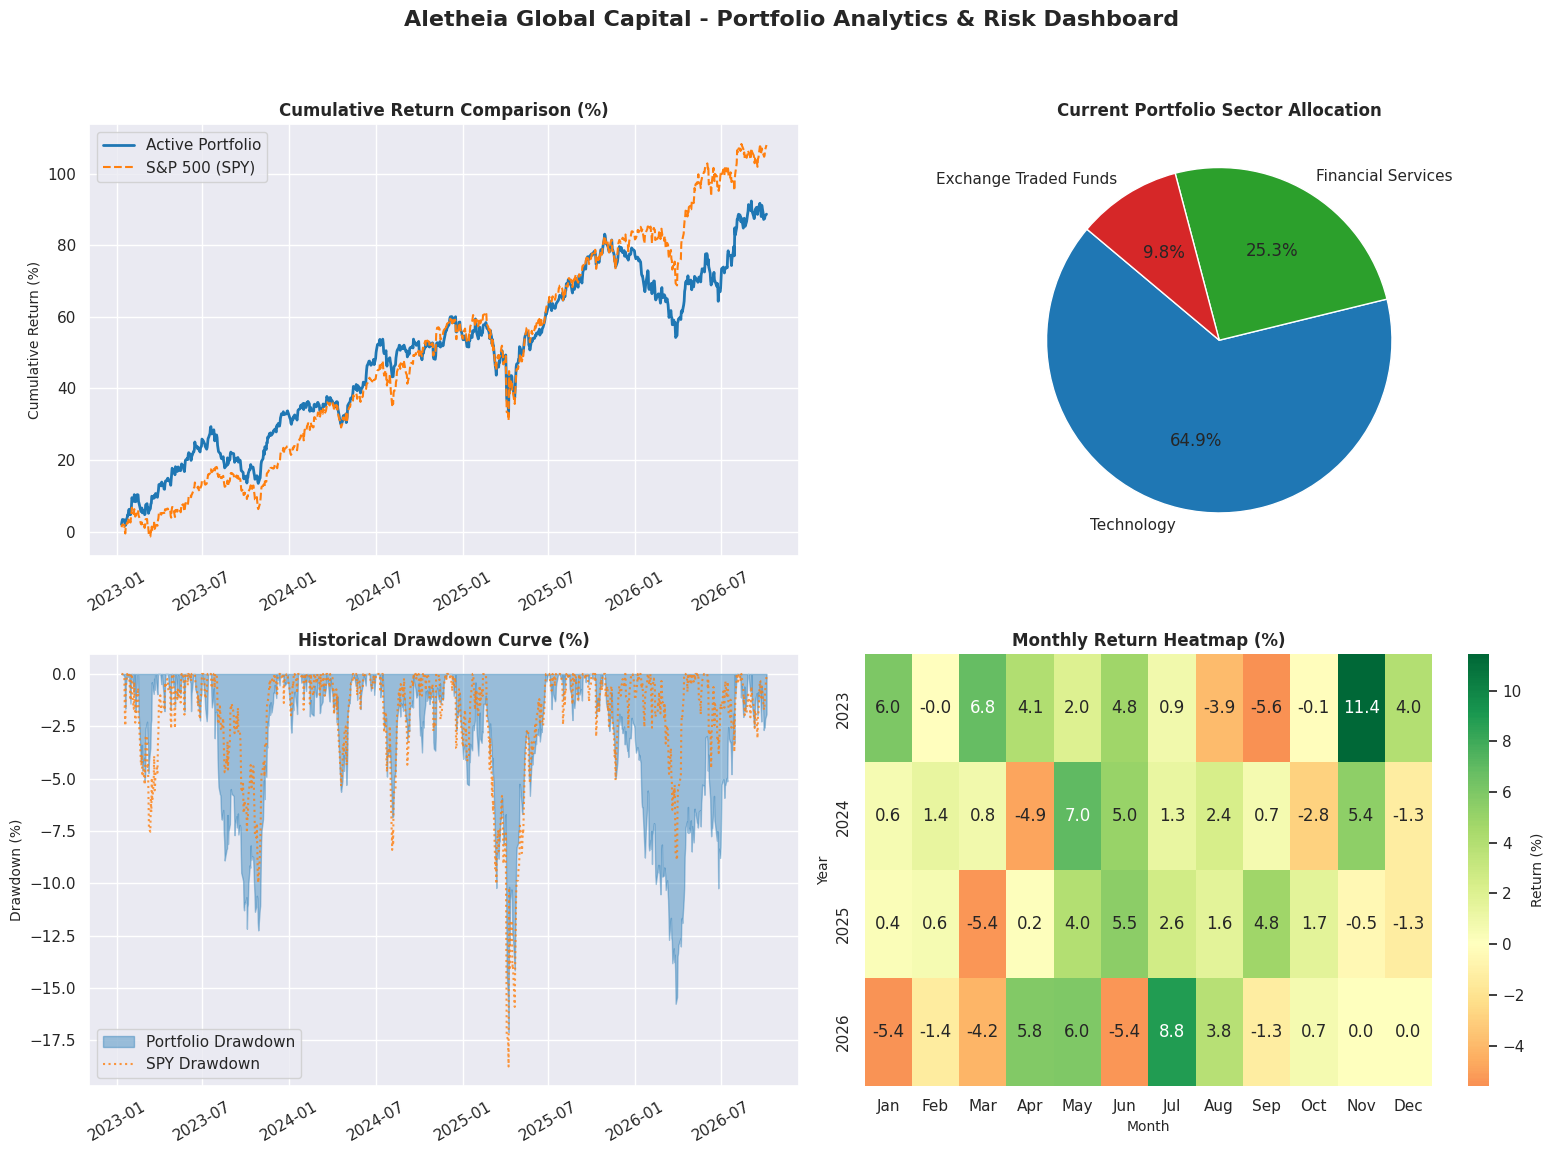

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Set style for professional financial dashboard
sns.set_theme(style="darkgrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Ensure indexes are DatetimeIndex to allow resampling
portfolio_daily_returns.index = pd.to_datetime(portfolio_daily_returns.index)
benchmark_returns.index = pd.to_datetime(benchmark_returns.index)

# Prepare Data
# Cumulative Returns (using exponential of cumsum of log returns)
portfolio_cum = (np.exp(portfolio_daily_returns.cumsum()) - 1) * 100
spy_cum = (np.exp(benchmark_returns.cumsum()) - 1) * 100

# Drawdowns
portfolio_drawdown = drawdowns * 100
portfolio_drawdown.index = pd.to_datetime(portfolio_drawdown.index)
spy_running_max = np.exp(benchmark_returns.cumsum()).cummax()
spy_drawdown = ((np.exp(benchmark_returns.cumsum()) - spy_running_max) / spy_running_max) * 100

# Monthly Returns Heatmap
portfolio_monthly_ret = portfolio_daily_returns.resample('ME').apply(lambda x: np.exp(x.sum()) - 1) * 100
heatmap_df = pd.DataFrame({
    'Year': portfolio_monthly_ret.index.year,
    'Month': portfolio_monthly_ret.index.month,
    'Return': portfolio_monthly_ret.values
})
heatmap_pivot = heatmap_df.pivot(index='Year', columns='Month', values='Return').fillna(0)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
heatmap_pivot.columns = [month_names[m-1] for m in heatmap_pivot.columns]

# Create 2x2 Dashboard Figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Aletheia Global Capital - Portfolio Analytics & Risk Dashboard', fontweight='bold', y=0.96)

# Plot 1: Cumulative Performance
axes[0, 0].plot(portfolio_cum.index, portfolio_cum, label='Active Portfolio', color='#1f77b4', linewidth=2)
axes[0, 0].plot(spy_cum.index, spy_cum, label='S&P 500 (SPY)', color='#ff7f0e', linestyle='--', linewidth=1.5)
axes[0, 0].set_title('Cumulative Return Comparison (%)', fontweight='bold')
axes[0, 0].set_ylabel('Cumulative Return (%)')
axes[0, 0].legend(loc='upper left')
axes[0, 0].tick_params(axis='x', rotation=30)

# Plot 2: Sector Allocation
sector_colors = ['#1f77b4', '#2ca02c', '#d62728']
axes[0, 1].pie(sector_df['allocation_percentage'], labels=sector_df['sector'], autopct='%1.1f%%', startangle=140, colors=sector_colors, wedgeprops={'edgecolor': 'white', 'linewidth': 1})
axes[0, 1].set_title('Current Portfolio Sector Allocation', fontweight='bold')

# Plot 3: Drawdown Curves
axes[1, 0].fill_between(portfolio_drawdown.index, portfolio_drawdown, 0, label='Portfolio Drawdown', color='#1f77b4', alpha=0.4)
axes[1, 0].plot(spy_drawdown.index, spy_drawdown, label='SPY Drawdown', color='#ff7f0e', linestyle=':', alpha=0.8)
axes[1, 0].set_title('Historical Drawdown Curve (%)', fontweight='bold')
axes[1, 0].set_ylabel('Drawdown (%)')
axes[1, 0].legend(loc='lower left')
axes[1, 0].tick_params(axis='x', rotation=30)

# Plot 4: Monthly Return Heatmap
sns.heatmap(heatmap_pivot, annot=True, fmt=".1f", cmap='RdYlGn', center=0, cbar_kws={'label': 'Return (%)'}, ax=axes[1, 1])
axes[1, 1].set_title('Monthly Return Heatmap (%)', fontweight='bold')
axes[1, 1].set_ylabel('Year')
axes[1, 1].set_xlabel('Month')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

## Final Portfolio Manager Dashboard Summary

### Subtask:
Create an executive summary and final KPI dashboard table representing the final recruiters-ready portfolio state.


## Summary:

### Q&A

* **What are the historical return and risk profiles of the individual assets within the portfolio?**
  * **AAPL**: Weight of 24.53% | Annualized Volatility of 25.68% | Total Return of +156.07% (Absolute P&L: +\$30,433.50) | Max Historical Drawdown of -33.36%.
  * **MSFT**: Weight of 30.19% | Annualized Volatility of 26.02% | Total Return of +118.82% (Absolute P&L: +\$28,518.00) | Max Historical Drawdown of -34.50%.
  * **JPM**: Weight of 18.87% | Annualized Volatility of 22.98% | Total Return of +165.90% (Absolute P&L: +\$24,885.60) | Max Historical Drawdown of -21.43%.
  * **TLT**: Weight of 26.42% | Annualized Volatility of 14.09% | Total Return of -26.56% (Absolute P&L: -\$5,578.00) | Max Historical Drawdown of -31.42%.

* **How did the active portfolio perform on an aggregate level compared to the S&P 500 benchmark?**
  * The portfolio achieved an **Annualized Return of 17.09%** with an **Annualized Volatility of 14.28%**, resulting in a solid **Sharpe Ratio of 1.20** ($R_f=0$).
  * It exhibited a **Beta of 0.77** relative to the S&P 500 (SPY), indicating defensive, lower-volatility market-matching characteristics while generating an **Annualized Alpha of 1.97%**.
  * The maximum aggregate portfolio drawdown was contained at **-17.10%**.

---

### Data Analysis Key Findings

* **Sector Concentration Risk**: The active portfolio is heavily concentrated in the **Technology** sector, which accounts for **64.94%** of current market value (\$102,451.50). **Financial Services** follows at **25.28%** (\$39,885.60), while **Exchange Traded Funds** (via the TLT bond holding) represents just **9.78%** (\$15,422.00).
* **Asset Performance Divergence**: Equity holdings (JPM, AAPL, and MSFT) drove the portfolio's exceptional gains, led by JPM (+165.90%) and AAPL (+156.07%). Conversely, fixed-income exposure via TLT acted as a significant drag, declining **-26.56%** from its average cost basis.
* **Drawdown Dynamics**: At the individual asset level, MSFT and AAPL experienced severe peak-to-trough historical drawdowns of **-34.50%** and **-33.36%** respectively. However, due to diversification benefits and low asset covariance, the overall portfolio's maximum historical drawdown was mitigated to just **-17.10%**.

---

### Insights or Next Steps

* **Rebalance Portfolio Sector Allocation**: The portfolio has a massive Technology sector exposure (64.94%). Action should be taken to reallocate capital away from overextended tech names (AAPL, MSFT) and into other cyclical, defensive, or value sectors to mitigate tech-specific thematic shocks.
* **Re-evaluate Fixed Income Strategy**: The TLT position underperformed significantly with a -26.56% return and a large -31.42% individual drawdown, failing to act as a proper portfolio hedge. Replacing TLT with shorter-duration Treasury bills or multi-asset alternative strategies should be explored to preserve capital and improve the overall Sharpe ratio.
